# 5장 2강: 부스팅 계열 모델의 원리와 발전

## 실습 목표

이번 실습에서는 **Ames Housing** 데이터를 이용하여 부스팅 계열 모델의 순차 학습 원리와 주요 모델의 차이를 확인합니다.

- AdaBoost와 Gradient Boosting의 순차 학습 원리를 이해합니다.
- Gradient Boosting이 이전 모델의 잔차를 보완하는 흐름을 확인합니다.
- XGBoost와 LightGBM을 같은 데이터에서 비교합니다.
- `learning_rate`, `n_estimators`, `max_depth`의 역할을 확인합니다.
- Early Stopping의 목적을 이해합니다.
- 부스팅이 단계적으로 편향을 줄여가는 이유를 설명합니다.

> 이 실습에서는 5장 2강 교안에서 다룬 내용만 사용합니다.

## 실습 환경 / 데이터

- Python
- pandas
- matplotlib
- scikit-learn
- xgboost
- lightgbm
- 데이터: `Ames_Housing.csv`

### 분석 목표

주택의 특성을 이용하여 `SalePrice`를 예측하는 회귀 문제입니다.

### 사용할 특성

- `OverallQual`
- `GrLivArea`
- `GarageCars`
- `GarageArea`
- `TotalBsmtSF`
- `1stFlrSF`
- `2ndFlrSF`
- `FullBath`
- `TotRmsAbvGrd`
- `YearBuilt`
- `YearRemodAdd`
- `Fireplaces`

예측 대상은 `SalePrice`입니다.

In [1]:
import xgboost
import lightgbm

print("xgboost :", xgboost.__version__)
print("lightgbm:", lightgbm.__version__)

xgboost : 3.4.1
lightgbm: 4.7.0


## 실습 준비

1. Ames Housing 데이터를 불러옵니다.
2. 사용할 숫자형 특성과 `SalePrice`를 선택합니다.
3. Train / Test 데이터로 분리합니다.
4. 같은 데이터에서 Gradient Boosting, XGBoost, LightGBM을 비교합니다.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import time

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostRegressor, GradientBoostingRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

from xgboost import XGBRegressor
from lightgbm import LGBMRegressor

house = pd.read_csv("Ames_Housing.csv")

features = [
    "OverallQual",
    "GrLivArea",
    "GarageCars",
    "GarageArea",
    "TotalBsmtSF",
    "1stFlrSF",
    "2ndFlrSF",
    "FullBath",
    "TotRmsAbvGrd",
    "YearBuilt",
    "YearRemodAdd",
    "Fireplaces"
]

X = house[features]
y = house["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Train 크기:", X_train.shape)
print("Test 크기:", X_test.shape)

print("\n[결측치]")
display(X.isna().sum().to_frame("missing"))

Train 크기: (1168, 12)
Test 크기: (292, 12)

[결측치]


,missing
OverallQual,0
GrLivArea,0
GarageCars,0
GarageArea,0
TotalBsmtSF,0
1stFlrSF,0
2ndFlrSF,0
FullBath,0
TotRmsAbvGrd,0
YearBuilt,0


---

# 필수 1. 부스팅의 순차 학습 원리 확인

## 문제 1. AdaBoost와 Gradient Boosting의 차이를 정리하세요.

### 요구사항

다음 두 모델이 이전 모델의 실수를 어떻게 보완하는지 각각 작성합니다.

- AdaBoost
- Gradient Boosting

### 확인 포인트

- AdaBoost는 틀린 샘플에 더 큰 가중치를 주는가?
- Gradient Boosting은 이전 모델의 잔차를 다음 모델이 학습하는가?

### Q1. AdaBoost와 Gradient Boosting은 각각 무엇에 집중하여 다음 모델을 학습하나요?

**답변:**  
#### AdaBoost : 이전 모델이 틀린 샘플의 가중치를 높여 다음 모델이 그 샘플에 더 집중하게 학습하는 방법
#### Gradient Boosting : 이전 모델이 남긴 잔차(실제값 - 예측값)을 다음 모델이 학습하도록 하는 방법


In [3]:
# AdaBoost: 틀린 샘플에 가중치를 높여 다음 모델이 그 샘플에 집중하게 합니다.

import numpy as np
from sklearn.metrics import mean_squared_error


def rmse(y_true, y_pred):
    """RMSE를 계산합니다."""
    return np.sqrt(mean_squared_error(y_true, y_pred))

ada = AdaBoostRegressor(
    estimator=DecisionTreeRegressor(max_depth=2, random_state=42),
    n_estimators=100,
    learning_rate=0.05,
    random_state=42
)
ada.fit(X_train, y_train)

ada_rmse = rmse(y_test, ada.predict(X_test))

# Gradient Boosting: 이전 모델의 잔차를 다음 모델이 예측하도록 학습합니다.
gb = GradientBoostingRegressor(
    n_estimators=100,
    learning_rate=0.05,
    max_depth=2,
    random_state=42
)
gb.fit(X_train, y_train)

gb_rmse = rmse(y_test, gb.predict(X_test))

compare_boost = pd.DataFrame({
    "model": ["AdaBoost", "Gradient Boosting"],
    "보완 방식": ["틀린 샘플의 가중치를 높임", "이전 모델의 잔차를 학습"],
    "test_rmse": [ada_rmse, gb_rmse]
})

print("[AdaBoost vs Gradient Boosting]")
display(compare_boost)

[AdaBoost vs Gradient Boosting]


,model,보완 방식,test_rmse
0,AdaBoost,틀린 샘플의 가중치를 높임,44814.378304
1,Gradient Boosting,이전 모델의 잔차를 학습,32559.186347


## 문제 2. Gradient Boosting의 단계별 성능 변화를 확인하세요.

### 요구사항

1. `GradientBoostingRegressor`를 사용합니다.
2. `n_estimators=100`
3. `learning_rate=0.05`
4. `max_depth=2`
5. `random_state=42`
6. 모델을 학습합니다.
7. `staged_predict()`를 사용해 나무가 추가될 때마다 Test RMSE를 계산합니다.
8. 나무 개수에 따른 Test RMSE를 선 그래프로 나타냅니다.

### 확인 포인트

- 순차적으로 나무가 추가되면서 예측 오차가 감소하는 구간을 확인했는가?
- 이전까지 설명하지 못한 부분을 다음 나무가 보완한다는 개념과 연결할 수 있는가?

,n_estimators,test_rmse
0,1,85132.584919
1,2,82772.040376
2,3,80552.512752
3,4,78473.344774
4,5,76549.974178


,n_estimators,test_rmse
95,96,32847.640819
96,97,32730.734170
97,98,32698.595181
98,99,32663.909690
99,100,32559.186347


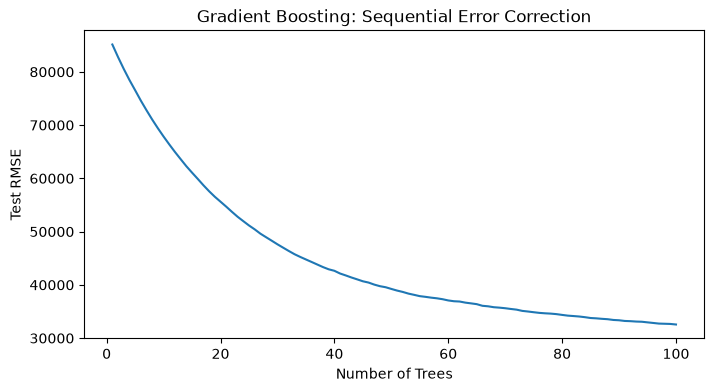

In [4]:
# TODO
# GradientBoostingRegressor를 학습하고
# staged_predict()를 이용해 단계별 Test RMSE를 확인하세요.
gb = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)

gb.fit(X_train, y_train)

stage_results = []

for stage, pred in enumerate(
    gb.staged_predict(X_test),
    start=1
):
    rmse = mean_squared_error(
        y_test,
        pred) ** 0.5
    stage_results.append({
        "n_estimators": stage,
        "test_rmse": rmse})

stage_df = pd.DataFrame(stage_results)

display(stage_df.head())
display(stage_df.tail())

plt.figure(figsize=(8, 4))
plt.plot(stage_df["n_estimators"], stage_df["test_rmse"])
plt.xlabel("Number of Trees")
plt.ylabel("Test RMSE")
plt.title("Gradient Boosting: Sequential Error Correction")
plt.show()

#### n_estimators=100인 의미 : 최대 100개의 순차적으로 보정을 하는 나무를 추가한다.
#### Learning_rate 0.05의 의미 : 새 나무의 보정값을 0.05배하여 현재 예측에 더 하겠다.
#### max_depth=2의 의미 : 개별 나무의 깊이를 최대 2개로 제한한다.

#### Train에서 남은 오차를 다음 나무가 학습한다.(잔차를 계속해서 줄여나가는 모델)
#### 잔차(실제값-예측값)을 지속적으로 줄여나가는 모델

#### RMSE : 예측 오차를 제곱하여 평균을 낸 뒤 제곱근을 취한다. -> 작을수록 좋은 값
#### 완벽한 예측은 0에 수렴한다.
#### 오차가 제곱이 되어 더 크게 반영되기 때문에 큰 오차를 탐지해낼 수 있다.

#### 판매가격이 달러라면 RMSE도 달러로 해석할 수 있다.
#### RMSE가 32,847라는 것은 제곱평균제곱근으로 요약한 오차의 크기가 32,847달러라는 의미

#### 나무가 많아질수록 Test의 오차는 무조건 내려가는가?
#### -> 아니요. 학습은 Train의 손실을 줄이는 방향으로 진행
#### Test의 정답으로 보정 나무를 학습하지는 않음
#### Train의 나무를 계속 추가하면 Train의 노이즈까지 학습하여 성능결과가 좋지 않을 수 있음.

#### Staged_predict와 Early Stopping
#### -> 100단계까지 학습한 뒤 Test 예측을 관찰하는 것. 중간에 가장 좋은 학습단계가 있어도(손실이 적은)
#### 100번을 채울때까지 멈추지 않음
#### -> Early Stopping은 N번만큼 학습했을떄 손실이 더 이상 줄어들지 않는 지점을 찾아서 모델을 종료

### Q2. 부스팅에서 나무를 순차적으로 추가하는 이유는 무엇인가요?

**답변:**  
#### 앞선 모델이 남긴 오차를 다음 모델이 학습하여 아직 설명이 충분히 되지 않은 패턴을 계속 보완하려고 함.

---

# 필수 2. XGBoost와 LightGBM 비교

## 문제 1. 두 모델을 같은 조건에서 학습하세요.

### 요구사항

다음 공통 설정을 사용합니다.

- `n_estimators=200`
- `learning_rate=0.05`
- `max_depth=3`
- `random_state=42`

다음 두 모델을 학습합니다.

- `XGBRegressor`
- `LGBMRegressor`

각 모델에 대해 다음을 확인합니다.

1. 학습 시간
2. Test RMSE

### 확인 포인트

- XGBoost와 LightGBM을 같은 데이터와 같은 주요 하이퍼파라미터 조건에서 비교했는가?
- LightGBM이 빠른 학습을 강점으로 갖는다는 교안 내용과 연결할 수 있는가?

In [5]:
# TODO
# XGBoost와 LightGBM의 학습 시간과 Test RMSE를 비교하세요.
models = {
    "XGBoost": XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        n_jobs=-1),

    "LightGBM": LGBMRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42,
        verbose=-1)}

comparison_results = []

for name, model in models.items():
    start_time = time.time()
    model.fit(X_train, y_train)

    elapsed = (time.time() - start_time)
    pred = model.predict(X_test)
    rmse = mean_squared_error(y_test, pred) ** 0.5

    comparison_results.append({
        "model": name,
        "test_rmse": rmse,
        "train_seconds": elapsed})

comparison_df = pd.DataFrame(comparison_results)
display(comparison_df)

,model,test_rmse,train_seconds
0,XGBoost,28405.320065,0.199212
1,LightGBM,31813.091613,0.040106


#### Depth-wise -> 뿌리에 가까운 깊이의 노드를 우선 확장(같은 깊이의 노드를 균등하게 확장하려고 함)
#### Leaf-wise -> 현재 잎들 중 손실을 가장 많이 줄일 분할을 우선 확장(손실 감소가 많았던 친구부터 확장하려고 함)
#### XGBoost의 기본적인 Depth-wise 성장을 따르고 LightGBM은 Leaf-wise를 따른다.

#### 현재 지표로만 대표적인 모델을 설정하는 것은 무리지만 다른 성능평가지표도 함꼐 체크해야함
#### 현재 지표로만 대표적인 모델을 설정해본다면 RMSE(오차 제곱근)과 시간 효율성이 좋은 XGBoost를 선택한다.

### Q3. XGBoost와 LightGBM의 기본 트리 성장 방식 차이는 무엇인가요?
#### XGBoost의 기본적인  Depth-wise 성장을 따르고 LightGBM은 Leaf-wise를 따른다.

### Q4. CatBoost의 구조적 특징과 강점은 무엇인가요?

**답변:**  
#### Symmetric Tree 구조 사용, 같은 깊이의 노드에 같은 분할 조건을 적용
#### 범주형 처리에 가장 강한 강점이 있음.

## 문제 2. learning_rate와 n_estimators의 관계를 확인하세요.

### 요구사항

다음 조합을 비교합니다.

```python
settings = [
    {"learning_rate": 0.1, "n_estimators": 50},
    {"learning_rate": 0.05, "n_estimators": 100},
    {"learning_rate": 0.01, "n_estimators": 300}
]
```

각 조합에 대해 `GradientBoostingRegressor(max_depth=2, random_state=42)`를 학습하고 다음을 확인합니다.

1. Test RMSE
2. 학습 시간

### 확인 포인트

- learning_rate가 작을수록 더 많은 나무가 필요할 수 있음을 확인했는가?
- 성능뿐 아니라 학습 시간도 함께 확인했는가?

In [8]:
import numpy as np
from sklearn.metrics import mean_squared_error


def rmse(y_true, y_pred):
    """RMSE를 계산합니다."""
    return np.sqrt(mean_squared_error(y_true, y_pred))

In [9]:
# TODO
# learning_rate / n_estimators 조합별 Test RMSE와 학습 시간을 비교하세요.
settings = [
    {"learning_rate": 0.1, "n_estimators": 50},
    {"learning_rate": 0.05, "n_estimators": 100},
    {"learning_rate": 0.01, "n_estimators": 300}
]

rows = []

for setting in settings:
    model = GradientBoostingRegressor(
        learning_rate=setting["learning_rate"],
        n_estimators=setting["n_estimators"],
        max_depth=2,
        random_state=42
    )

    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start

    rows.append({
        "learning_rate": setting["learning_rate"],
        "n_estimators": setting["n_estimators"],
        "test_rmse": rmse(y_test, model.predict(X_test)),
        "train_time_sec": train_time
    })

setting_df = pd.DataFrame(rows)

print("[learning_rate / n_estimators 조합 비교]")
display(setting_df)

[learning_rate / n_estimators 조합 비교]


,learning_rate,n_estimators,test_rmse,train_time_sec
0,0.10,50,31791.283180,0.045532
1,0.05,100,32559.186347,0.083417
2,0.01,300,37165.991330,0.248094


#### Learning_rate의 0.05에 의미(학습률 : 0.05배만큼 더 공부하겠다?)
#### 새 나무가 출력한 보정값을 0.05배하여 더한다는 뜻

#### 작은 학습률에서 더 많은 나무가 필요한 경우가 있는지?
#### Learning_rate가 작으면 유용한 패턴을 누적하여 학습하는데에 오랜 시간과 단계가 필요할 수 있다.
#### 작은 학습률은 점진적인 학습을 가능하게 하지만
#### 주어진 나무의 수가 작다면 보장이 덜 된 상태로 학습이 끝날 가능성이 있다.


### Q5. learning_rate를 작게 만들면 왜 n_estimators를 함께 늘려야 할 수 있나요?

**답변:**  
#### 각 나무가 최종 예측에 반영되는 비율이 작기 때문에 같은 정도의 오차 보완을 위해 더 많은 단계가 필요할 수 있다.

---

# 과제 1. Early Stopping과 부스팅 모델 선택(과적합 해결방법)

## 배경

교안에서는 `n_estimators`를 충분히 크게 설정하고, 검증 성능이 더 이상 좋아지지 않으면 학습을 멈추는 **Early Stopping**을 소개했습니다.

이번 과제에서는 XGBoost에서 이 흐름을 적용합니다.

> 과제는 필수 실습에서 사용한 모델과 하이퍼파라미터를 그대로 활용하는 수준입니다.

## 요구사항

1. Train 데이터를 다시 Train / Validation으로 나눕니다.
2. `XGBRegressor`를 사용합니다.
3. `n_estimators=1000`
4. `learning_rate=0.05`
5. `max_depth=3`
6. `early_stopping_rounds=20`
7. Train 데이터로 학습하고 Validation 데이터를 `eval_set`으로 전달합니다.
8. Test 데이터의 RMSE를 계산합니다.
9. 실제로 사용된 나무 수를 확인합니다.
10. `n_estimators=1000`을 모두 사용하지 않고 중간에 멈췄다면 그 이유를 설명합니다.

11. Q7에서 배깅·랜덤포레스트·부스팅의 작동 원리와 편향·분산, 과적합에 미치는 영향을 비교합니다. 새로운 모델 학습 코드는 요구하지 않습니다.

### 확인 포인트

- Early Stopping이 Validation 성능을 기준으로 동작한다는 점을 이해했는가?
- 불필요하게 많은 나무를 쌓는 것을 막는 목적을 설명할 수 있는가?
- 과적합 방지와 학습 시간 절약이라는 두 가지 의미를 설명할 수 있는가?
- 배깅의 부트스트랩·예측 결합, 랜덤포레스트의 특성 무작위 선택, 부스팅의 순차적 오류 보완을 설명할 수 있는가?
- 각 방식이 편향·분산에 미치는 일반적인 영향과 과적합 가능성을 구분할 수 있는가?


In [10]:
# TODO
# XGBoost에 Early Stopping을 적용하세요.
X_train_sub, X_valid, y_train_sub, y_valid = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42
)

early_model = XGBRegressor(
    n_estimators=1000,
    learning_rate=0.05,
    max_depth=3,
    random_state=42,
    n_jobs=-1,
    eval_metric="rmse",
    early_stopping_rounds=20
)

early_model.fit(
    X_train_sub,
    y_train_sub,
    eval_set=[
         (X_valid, y_valid)
    ],
    verbose=False
)

early_pred = early_model.predict(
    X_test
)

early_rmse = mean_squared_error(
    y_test,
    early_pred
) ** 0.5

print("Test RMSE:", early_rmse)
print("예측에 사용된 나무 수:", early_model.best_iteration + 1)
print("실제로 학습한 나무 수:", early_model.get_booster().num_boosted_rounds())

Test RMSE: 30332.878531389004
예측에 사용된 나무 수: 108
실제로 학습한 나무 수: 128


#### 예측한 나무의 수와 실제로 사용된 나무의 수가 다르다 -> 이럴때 많이 사용한다. 
#### Early Stopping을 사용하는 이유
#### 학습을 멈출 수 있는 장치인 Early Stopping이 없다면 최적의 RMSE를 보여도 모델은 멈추지 않고 학습할 수 있다.
#### Early Stopping은 가장 좋은 단계의 나무 수를 통해 손실이 갱신이 없으면 학습을 강제로 종료하여
#### 최적의 성능과 시간적 효율을 높이기 위함이다.

### Q6. Early Stopping은 어떤 상황에서 학습을 멈추나요?
**답변:**  
#### Validation 세트의 성능이 정해둔 횟수 동안 연속으로 개선되지 않을 때(갱신이 없을때)

### Q7. 배깅·랜덤포레스트·부스팅의 작동 원리와 편향·분산에 미치는 영향을 비교하세요.

다음 항목을 포함하여 각 방법을 설명하세요.

1. **배깅:** 부트스트랩 표본을 만드는 방법과 여러 모델의 예측을 결합하는 방법, 분산 감소의 이유
2. **랜덤포레스트:** 배깅에 더해 각 노드의 분할 후보 특성을 무작위로 선택하는 이유와 트리 간 상관·분산에 미치는 영향
3. **부스팅:** 이전 모델의 오류를 순차적으로 보완하는 원리와 편향 감소의 관계, 과적합 가능성 및 이를 줄이는 방법

> 편향·분산에 대한 효과는 일반적인 경향입니다. 한 방법이 편향 또는 분산만 바꾸거나 과적합을 항상 막는다고 단정하지 마세요.

**답변:**

- 배깅:
원본 데이터에서 중복을 허용해 같은 크기로 다시 뽑는 부트스트랩 표본을 여러 개 만들고, 각각에 모델을 학습시킨다. 예측은 회귀면 평균, 분류면 다수결로 합친다.
나무마다 학습 데이터가 달라 틀리는 지점도 달라진다. 어떤 나무는 높게, 어떤 나무는 낮게 틀리는데 평균을 내면 이 오차들이 서로 상쇄되어 분산이 줄어든다. 편향은 거의 그대로여서, 편향이 낮고 분산이 큰 깊은 나무에 쓸 때 효과가 크다.

- 랜덤포레스트:
각 노드를 나눌 때 무작위로 뽑은 일부 특성 중에서만 기준을 고른다. 부트스트랩만 쓰면 강한 특성이 모든 나무의 윗부분을 차지해 나무들이 서로 비슷해지기 때문이다.
특성을 제한하면 나무마다 다른 기준으로 자라 트리 간 상관이 낮아진다. 나무들이 비슷할수록 평균을 내도 분산이 덜 줄어드는데, 상관을 낮추면 같은 나무 수로도 분산 감소 효과가 커진다. 편향은 거의 그대로이거나 개별 나무 기준으로는 조금 늘 수 있지만, 보통 분산 감소 이득이 더 크다.

- 부스팅:
나무를 순서대로 쌓으면서 앞 모델이 틀린 부분을 다음 모델이 보완한다. AdaBoost는 틀린 샘플의 가중치를 높이고, Gradient Boosting은 남은 오차(잔차)를 다음 모델이 예측한다.
단계를 거듭할수록 아직 설명하지 못한 패턴을 잡아내므로 편향이 줄어든다. 배깅이 분산을 줄인다면 부스팅은 편향을 줄인다는 점이 핵심 차이다.
대신 나무를 너무 많이 쌓으면 Train 데이터의 노이즈까지 맞추려 들어 과적합 위험이 커진다. 이를 줄이려면 `learning_rate`를 낮추고, Early Stopping으로 반복을 멈추며, `max_depth`나 `subsample` 같은 설정으로 복잡도를 제한한다.

> 위 편향·분산 효과는 일반적인 경향이며, 데이터와 하이퍼파라미터에 따라 달라질 수 있다.


---

# 실습 마무리

아래 질문에 짧게 답해보세요.

1. 부스팅은 여러 모델을 병렬로 학습하나요, 순차적으로 학습하나요?
-> 순차학습

2. AdaBoost는 이전 모델이 틀린 샘플을 어떻게 처리하나요?
-> 이전 모델이 틀린 샘플의 가중치를 높인다.

3. Gradient Boosting은 다음 모델이 무엇을 학습하나요?
-> 이전 모델이 남긴 잔차를 다음 모델이 학습한다.

4. XGBoost와 LightGBM의 기본 트리 성장 방식은 어떻게 다른가요?
-> 1. XGBoost : Level-wise
-> 2. LightGBM : Leaf-wise 

5. `learning_rate`와 `n_estimators`는 어떤 관계가 있나요?
-> Learning_rate가 작을수록 일반적으로 더 많은 나무가 필요할 수 있다.

6. Early Stopping을 사용하는 이유는 무엇인가요?
-> Validation 성능이 더 이상 좋아지지 않을 떄 (학습 손실이 더 이상 줄어들지 않을 때)
-> 학습을 멈춰서 과적합과 불필요한 학습을 줄인다.

7. 부스팅은 편향과 분산 중 어떤 문제를 줄이는 데 특히 초점을 두나요?
-> 단계적으로 이전 오차를 보완하면서 편향을 줄이는 데 초점을 둔다.
